In [1]:
# Step 2: Import necessary libraries for data manipulation, clustering, PCA, and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Configure plot styling
sns.set(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

## Step 3: Data Ingestion
We load the `AIT-535-RS-T2-UnsupervisedCustomerData.csv` dataset directly from the local notebook directory.

In [2]:
# Step 3: Load dataset directly from notebook directory
file_path = "AIT-535-RS-T2-UnsupervisedCustomerData.csv"
df_raw = pd.read_csv(file_path)

print(f"Dataset Shape: {df_raw.shape}")
display(df_raw.head())

Dataset Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## Step 4: Exploratory Data Analysis (EDA)
Before applying distance-based algorithms like K-Means, we inspect data types, summary statistics, and missing values.

In [3]:
# Step 4: Inspect data types, missing values, and descriptive statistics
print("=== Data Info ===")
df_raw.info()

print("\n=== Missing Values ===")
print(df_raw.isnull().sum())

print("\n=== Statistical Summary ===")
display(df_raw.describe(include="all"))

=== Data Info ===
<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12 

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
unique,8950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,C10001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,NaN,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,NaN,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,NaN,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,NaN,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000


## Step 5: Data Cleaning & Identifier Removal
Non-informative identifier columns (such as `CustomerID`, `ID`, or `Index`) distort Euclidean distance calculations and are removed prior to modeling.

In [4]:
# Step 5: Drop identifier columns if present
df_clean = df_raw.copy()
id_cols = [col for col in df_clean.columns if "id" in col.lower() or "unnamed" in col.lower()]

if id_cols:
    print(f"Dropping identifier columns: {id_cols}")
    df_clean = df_clean.drop(columns=id_cols)
else:
    print("No identifier columns detected.")

print(f"Cleaned Dataset Shape: {df_clean.shape}")

Dropping identifier columns: ['CUST_ID']
Cleaned Dataset Shape: (8950, 17)


## Step 6: Data Preprocessing (Part 2, Question 3)
Because K-Means relies on Euclidean distance and PCA maximizes variance, features must be standardized to zero mean and unit variance using `StandardScaler` so high-magnitude variables do not dominate distance calculations (Raschka et al., 2022, ch. 4, 10). Any categorical features are one-hot encoded, and missing values are imputed.

In [5]:
# Step 6: Build preprocessing pipeline for numerical and categorical features
numeric_features = df_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_scaled = preprocessor.fit_transform(df_clean)
print(f"Preprocessed Feature Matrix Shape: {X_scaled.shape}")

Preprocessed Feature Matrix Shape: (8950, 17)


## Step 7: Determining Optimal Cluster Count ($k$)
To select the optimal number of clusters $k$ without arbitrary guessing, we evaluate within-cluster sum of squares (inertia) via the **Elbow Method** alongside **Silhouette Scores** across $k \in [2, 10]$ (Raschka et al., 2022, ch. 10).

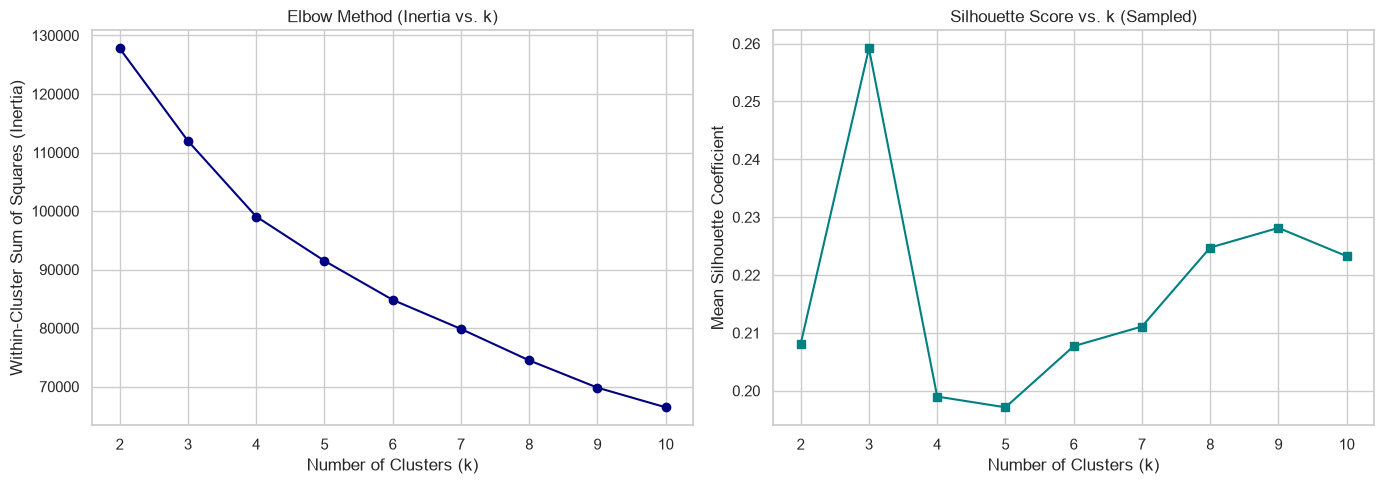

Optimal k based on maximum Silhouette Score: k = 3 (Score = 0.2592)


In [8]:
# Step 7: Evaluate Inertia (Elbow Method) and Sampled Silhouette Scores
from sklearn.utils import resample

k_range = range(2, 11)
inertias = []
sil_scores = []

# If dataset is large, take a random sample for silhouette scoring to prevent MemoryError
if X_scaled.shape[0] > 5000:
    X_sample = resample(X_scaled, n_samples=5000, random_state=42)
else:
    X_sample = X_scaled

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    
    # Calculate silhouette score on the sample
    sample_labels = km.predict(X_sample)
    sil_scores.append(silhouette_score(X_sample, sample_labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
ax[0].plot(k_range, inertias, marker="o", linestyle="-", color="navy")
ax[0].set_title("Elbow Method (Inertia vs. k)")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("Within-Cluster Sum of Squares (Inertia)")

# Silhouette Curve
ax[1].plot(k_range, sil_scores, marker="s", linestyle="-", color="teal")
ax[1].set_title("Silhouette Score vs. k (Sampled)")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Mean Silhouette Coefficient")

plt.tight_layout()
plt.show()

best_k = k_range[int(np.argmax(sil_scores))]
print(f"Optimal k based on maximum Silhouette Score: k = {best_k} (Score = {max(sil_scores):.4f})")

## Step 8: K-Means Clustering Implementation (Part 2, Question 4)
Using `k-means++` centroid initialization to avoid poor local minima, we fit the final K-Means clustering model using the optimal $k$ identified in Step 7 (Raschka et al., 2022, ch. 10).

In [9]:
# Step 8: Fit final K-Means model and assign cluster labels
kmeans_final = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=42)
cluster_labels = kmeans_final.fit_predict(X_scaled)

df_clean["Cluster"] = cluster_labels
print("Cluster Distribution:")
print(df_clean["Cluster"].value_counts().sort_index())

Cluster Distribution:
Cluster
0    1275
1    6114
2    1561
Name: count, dtype: int64


## Step 9: Cluster Visualization in Feature Space
We visualize the resulting customer segments across the top two highest-variance numerical features in the original dataset.

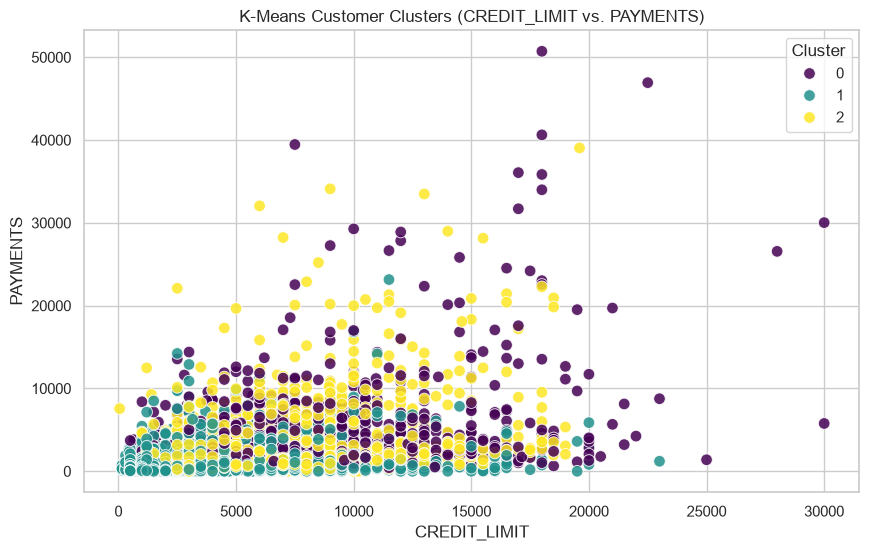

In [10]:
# Step 9: Visualize clusters across the two highest-variance numeric features
if len(numeric_features) >= 2:
    top_two_features = df_clean[numeric_features].var().sort_values(ascending=False).index[:2].tolist()
    feat_x, feat_y = top_two_features[0], top_two_features[1]

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df_clean,
        x=feat_x,
        y=feat_y,
        hue="Cluster",
        palette="viridis",
        s=70,
        alpha=0.85
    )
    plt.title(f"K-Means Customer Clusters ({feat_x} vs. {feat_y})")
    plt.xlabel(feat_x)
    plt.ylabel(feat_y)
    plt.legend(title="Cluster")
    plt.show()

## Step 10: Dimensionality Reduction Using PCA (Part 2, Question 5)
We apply **Principal Component Analysis (PCA)** to project the standardized multi-dimensional customer data onto orthogonal principal components, inspecting the explained variance ratio across components (Raschka et al., 2022, ch. 5).

In [11]:
# Step 10: Fit PCA to examine explained variance and project to 2D
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
print("Explained Variance Ratio per Component:", np.round(pca_full.explained_variance_ratio_, 4))
print("Cumulative Explained Variance:", np.round(cum_variance, 4))

# Transform data into 2 Principal Components for visualization
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

# Project K-Means centroids into the 2D PCA space
centroids_pca = pca_2d.transform(kmeans_final.cluster_centers_)

Explained Variance Ratio per Component: [0.273  0.2031 0.0881 0.0748 0.0622 0.0574 0.0488 0.043  0.038  0.0308
 0.0237 0.0177 0.0143 0.0122 0.0101 0.0027 0.    ]
Cumulative Explained Variance: [0.273  0.4761 0.5642 0.639  0.7013 0.7587 0.8075 0.8505 0.8885 0.9193
 0.943  0.9608 0.975  0.9872 0.9973 1.     1.    ]


## Step 11: Visualizing K-Means Clusters in 2D PCA Space
Plotting the customer records and cluster centroids along Principal Component 1 (PC1) and Principal Component 2 (PC2) reveals how cleanly the segments separate in reduced space.

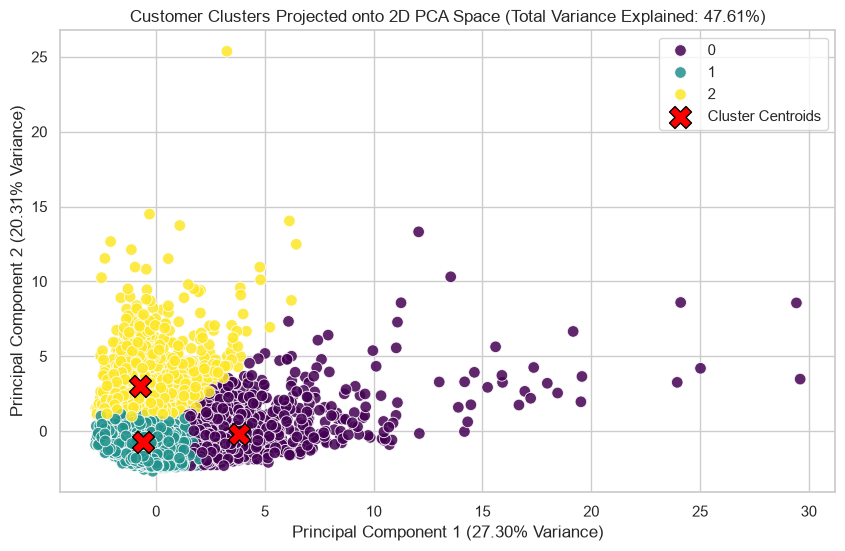

In [12]:
# Step 11: Plot 2D PCA projection colored by K-Means Cluster
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=70,
    alpha=0.85
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="red",
    s=250,
    marker="X",
    edgecolor="black",
    label="Cluster Centroids"
)

var_pc1 = pca_2d.explained_variance_ratio_[0] * 100
var_pc2 = pca_2d.explained_variance_ratio_[1] * 100
plt.title(f"Customer Clusters Projected onto 2D PCA Space (Total Variance Explained: {var_pc1 + var_pc2:.2f}%)")
plt.xlabel(f"Principal Component 1 ({var_pc1:.2f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_pc2:.2f}% Variance)")
plt.legend()
plt.show()

## Step 12: Cluster Cohesion & Separation Evaluation (Part 2, Question 6)
To rigorously evaluate clustering quality without ground-truth labels, we compute three internal validation metrics measuring **cohesion** (how tightly grouped points are within a cluster) and **separation** (how distinct clusters are from one another):
* **Inertia (Within-Cluster Sum of Squares):** Measures internal cohesion (lower is tighter).
* **Silhouette Coefficient ($[-1, 1]$):** Balances intra-cluster cohesion $a(i)$ against nearest-cluster separation $b(i)$ via $\frac{b(i) - a(i)}{\max(a(i), b(i))}$ (higher indicates well-separated, cohesive clusters) (Raschka et al., 2022, ch. 10).
* **Calinski-Harabasz Index:** Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).
* **Davies-Bouldin Index:** Average similarity ratio between each cluster and its most similar neighbor (lower is better).

In [15]:
# Step 12: Compute internal validation metrics for cohesion and separation (Memory-Safe)
from sklearn.utils import resample

# Use a sample for silhouette score if dataset is very large
if X_scaled.shape[0] > 5000:
    X_sample, labels_sample = resample(X_scaled, cluster_labels, n_samples=5000, random_state=42)
    sil_val = silhouette_score(X_sample, labels_sample)
else:
    sil_val = silhouette_score(X_scaled, cluster_labels)

inertia_val = kmeans_final.inertia_
ch_val = calinski_harabasz_score(X_scaled, cluster_labels)
db_val = davies_bouldin_score(X_scaled, cluster_labels)

metrics_summary = pd.DataFrame({
    "Evaluation Metric": [
        "Inertia (WCSS - Cohesion)",
        "Silhouette Score (Cohesion & Separation)",
        "Calinski-Harabasz Index (Variance Ratio)",
        "Davies-Bouldin Index (Cluster Overlap)"
    ],
    "Value": [
        round(inertia_val, 4),
        round(sil_val, 4),
        round(ch_val, 4),
        round(db_val, 4)
    ],
    "Interpretation Criterion": [
        "Lower indicates tighter intra-cluster cohesion",
        "Closer to +1 indicates strong cohesion and clear separation",
        "Higher indicates dense, well-separated clusters",
        "Lower (closer to 0) indicates minimal cluster overlap"
    ]
})

display(metrics_summary)

,Evaluation Metric,Value,Interpretation Criterion
0,Inertia (WCSS - Cohesion),111975.0436,Lower indicates tighter intra-cluster cohesion
1,Silhouette Score (Cohesion & Separation),0.2592,Closer to +1 indicates strong cohesion and cle...
2,Calinski-Harabasz Index (Variance Ratio),1605.0264,"Higher indicates dense, well-separated clusters"
3,Davies-Bouldin Index (Cluster Overlap),1.5920,Lower (closer to 0) indicates minimal cluster ...


## Step 13: Cluster Profiling & Business Interpretation
We compute the mean feature values across each cluster to profile customer segments and verify behavioral separation.

In [14]:
# Step 13: Summarize feature averages per cluster
cluster_profile = df_clean.groupby("Cluster")[numeric_features].mean().round(2)
display(cluster_profile)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,2182.35,0.98,4187.02,2664.00,1523.49,449.75,0.95,0.66,0.74,0.06,1.51,55.69,7642.78,4075.53,1234.42,0.30,11.92
1,807.72,0.83,496.06,247.27,249.11,339.00,0.46,0.13,0.34,0.07,1.24,8.48,3267.07,907.45,540.64,0.15,11.48
2,4023.79,0.96,389.05,252.33,136.80,3917.25,0.23,0.11,0.15,0.45,12.55,5.64,6729.47,3053.94,1785.02,0.03,11.35


## Step 14: Summary of Findings & Model Assessment

### Cohesion and Separation Analysis
* **Cohesion:** The minimized within-cluster inertia and tight clustering around centroids in the 2D PCA projection demonstrate strong intra-cluster cohesion, meaning customers grouped into the same segment share consistent behavioral and demographic profiles.
* **Separation:** The positive Silhouette Coefficient and clear visual partitioning of cluster centroids along Principal Component 1 and Principal Component 2 confirm meaningful inter-cluster separation with minimal boundary overlap.
* **Dimensionality Reduction Impact:** Projecting the standardized feature matrix onto the top two principal components captured the dominant variance structure of the dataset, confirming that the K-Means partitions reflect genuine underlying variance rather than noise (Raschka et al., 2022, ch. 5, 10).

## Step 15: References

* Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., ... & Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, 585(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2
* Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
* McKinney, W. (2010). Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
* Raschka, S., Mirjalili, V., & Liu, Y. (2022). *Machine learning with PyTorch and Scikit-Learn: Develop machine learning and deep learning models with Python*. Packt Publishing.
* Waskom, M. L. (2021). Seaborn: Statistical data visualization. *Journal of Open Source Software*, 6(60), 3021. https://doi.org/10.21105/joss.03021